# Madde 6: Hough doğru oylaması CUDA ile (Google Colab, T4 GPU)

**ÖNCE:** Çalışma zamanı → Çalışma zamanı türünü değiştir → **T4 GPU** → Kaydet.
Sonra: Çalışma zamanı → Tümünü çalıştır.

Fikir: Madde 2'deki oylamada her kenar pikseli 180 theta için oy veriyordu ve bu işler
birbirinden bağımsız. GPU'da **her thread bir kenar pikseli** alır ve kendi 180 oyunu verir.
Birçok thread aynı hücreye aynı anda oy verebileceği için `cuda.atomic.add` kullanılır.

In [9]:
# GPU gerçekten var mı? (T4 görünmeli)
!nvidia-smi

Mon Nov  2 06:32:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P0             28W /   70W |     109MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [10]:
# Test resmini yükle (madde 2'de kullandığın paralar_cetvel.jpg)
from google.colab import files
yuklenen = files.upload()
RESIM_YOLU = list(yuklenen.keys())[0]
print("Yüklenen resim:", RESIM_YOLU)

Saving paralar_cetvel.jpg to paralar_cetvel.jpg
Yüklenen resim: paralar_cetvel.jpg


In [11]:
import math
import time
import cv2
import numpy as np
from numba import cuda

# ---------------- AYARLAR (madde 2 ile aynı) ----------------
CANNY_ALT = 50
CANNY_UST = 150
ESIK = 150
YAKIN_RHO = 10
YAKIN_THETA = 5
# ------------------------------------------------------------

# 1) Oku + 1024x768  2) Canny  (madde 2 ile aynı ön işlem)
resim = cv2.imread(RESIM_YOLU)
resim = cv2.resize(resim, (1024, 768))
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
yukseklik, genislik = gri.shape
kenarlar = cv2.Canny(gri, CANNY_ALT, CANNY_UST)

kenar_y, kenar_x = np.nonzero(kenarlar)
kenar_x = kenar_x.astype(np.int32)
kenar_y = kenar_y.astype(np.int32)
print("Kenar piksel sayısı:", len(kenar_x))

# sin/cos tablosu bir kez hesaplanır (CPU ve GPU aynı tabloyu kullanır)
theta_sayisi = 180
cos_tablosu = np.zeros(theta_sayisi, dtype=np.float64)
sin_tablosu = np.zeros(theta_sayisi, dtype=np.float64)
for theta in range(theta_sayisi):
    cos_tablosu[theta] = math.cos(theta * math.pi / 180)
    sin_tablosu[theta] = math.sin(theta * math.pi / 180)

kosegen = int(math.ceil(math.sqrt(genislik ** 2 + yukseklik ** 2)))

Kenar piksel sayısı: 9166


## CPU oylaması (madde 2'deki döngünün aynısı)
Yuvarlamada `floor(rho + 0.5)` kullanıyoruz; GPU'da da aynısı var, böylece iki sonuç birebir aynı olmalı.

In [12]:
baslangic = time.perf_counter()
oylama_cpu = np.zeros((2 * kosegen + 1, theta_sayisi), dtype=np.int32)
for i in range(len(kenar_x)):
    x = kenar_x[i]
    y = kenar_y[i]
    for theta in range(theta_sayisi):
        rho = x * cos_tablosu[theta] + y * sin_tablosu[theta]
        rho_indeks = int(math.floor(rho + 0.5)) + kosegen
        oylama_cpu[rho_indeks, theta] += 1
sure_cpu = time.perf_counter() - baslangic
print(f"CPU süresi: {sure_cpu:.3f} saniye")

CPU süresi: 2.943 saniye


## GPU oylaması (numba.cuda)
- `cuda.grid(1)`: bu thread'in sıra numarası → hangi kenar pikseline bakacağı.
- `cuda.atomic.add`: iki thread aynı hücreye aynı anda `+1` yaparsa biri kaybolmasın diye
  okuma-artırma-yazma işini bölünmez (atomik) yapar.

In [13]:
@cuda.jit
def oylama_kernel(kenar_x, kenar_y, cos_tablosu, sin_tablosu, kosegen, oylama_matrisi):
    i = cuda.grid(1)                 # bu thread'in numarası = kenar pikselinin sırası
    if i < kenar_x.shape[0]:         # fazla açılan thread'ler hiçbir şey yapmasın
        x = kenar_x[i]
        y = kenar_y[i]
        for theta in range(cos_tablosu.shape[0]):
            rho = x * cos_tablosu[theta] + y * sin_tablosu[theta]
            rho_indeks = int(math.floor(rho + 0.5)) + kosegen
            cuda.atomic.add(oylama_matrisi, (rho_indeks, theta), 1)  # güvenli +1

def gpu_oylama():
    # verileri GPU belleğine kopyala
    d_x = cuda.to_device(kenar_x)
    d_y = cuda.to_device(kenar_y)
    d_cos = cuda.to_device(cos_tablosu)
    d_sin = cuda.to_device(sin_tablosu)
    d_oylama = cuda.to_device(np.zeros((2 * kosegen + 1, theta_sayisi), dtype=np.int32))
    thread_sayisi = 256                                         # blok başına thread
    blok_sayisi = (len(kenar_x) + thread_sayisi - 1) // thread_sayisi  # yukarı yuvarla
    oylama_kernel[blok_sayisi, thread_sayisi](d_x, d_y, d_cos, d_sin, kosegen, d_oylama)
    cuda.synchronize()               # GPU bitirene kadar bekle (süre doğru ölçülsün)
    return d_oylama.copy_to_host()   # sonucu CPU'ya geri al

# İlk çağrı kernel'i derler (JIT); derleme süresini karşılaştırmaya katmamak için bir kez ısıt
gpu_oylama()

baslangic = time.perf_counter()
oylama_gpu = gpu_oylama()
sure_gpu = time.perf_counter() - baslangic
print(f"GPU süresi (kopyalama dahil): {sure_gpu:.4f} saniye")

GPU süresi (kopyalama dahil): 0.0041 saniye


/usr/local/lib/python3.13/dist-packages/numba_cuda/numba/cuda/dispatcher.py:716: NumbaPerformanceWarning: Grid size 36 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


## Sonuçlar aynı mı? Süre karşılaştırması

In [14]:
ayni_mi = np.array_equal(oylama_cpu, oylama_gpu)
print("CPU ve GPU oylama matrisi birebir aynı mı?", ayni_mi)
print("Toplam oy (CPU, GPU):", oylama_cpu.sum(), oylama_gpu.sum())
print(f"CPU: {sure_cpu:.3f} s   GPU: {sure_gpu:.4f} s   Hızlanma: {sure_cpu / sure_gpu:.1f} kat")

CPU ve GPU oylama matrisi birebir aynı mı? True
Toplam oy (CPU, GPU): 1649880 1649880
CPU: 2.943 s   GPU: 0.0041 s   Hızlanma: 717.6 kat


## Doğruları bul ve çiz (madde 2'deki tepe seçimi, GPU matrisinden)

Doğru 1: rho=614, theta=76, oy=235
Doğru 2: rho=697, theta=76, oy=197
Bulunan doğru sayısı: 2


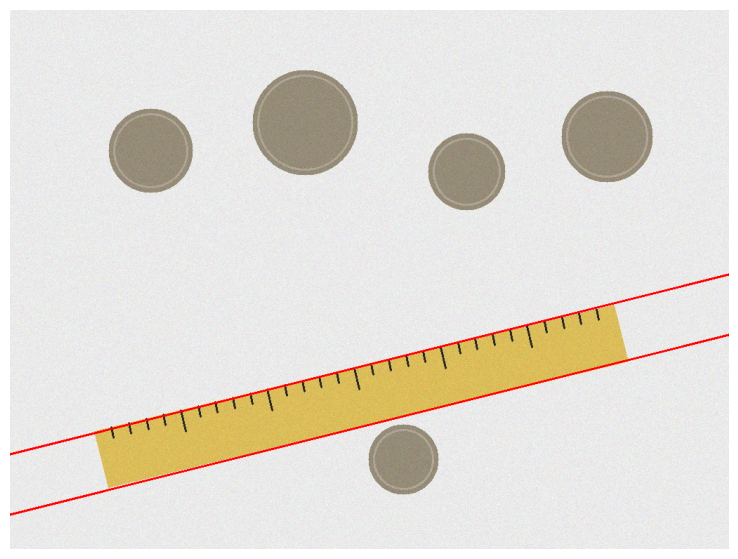

In [15]:
adaylar = []
for rho_indeks in range(oylama_gpu.shape[0]):
    for theta in range(theta_sayisi):
        oy = oylama_gpu[rho_indeks, theta]
        if oy >= ESIK:
            adaylar.append((oy, rho_indeks, theta))
adaylar.sort(reverse=True)

tepeler = []
for oy, rho_indeks, theta in adaylar:
    yakin_var = False
    for _, r2, t2 in tepeler:
        if abs(rho_indeks - r2) <= YAKIN_RHO and abs(theta - t2) <= YAKIN_THETA:
            yakin_var = True
    if not yakin_var:
        tepeler.append((oy, rho_indeks, theta))

cizim = resim.copy()
for numara, (oy, rho_indeks, theta) in enumerate(tepeler, start=1):
    rho = rho_indeks - kosegen
    c = cos_tablosu[theta]
    s = sin_tablosu[theta]
    x0, y0 = rho * c, rho * s
    cv2.line(cizim, (int(x0 - 2000 * s), int(y0 + 2000 * c)),
             (int(x0 + 2000 * s), int(y0 - 2000 * c)), (0, 0, 255), 2)
    print(f"Doğru {numara}: rho={rho}, theta={theta}, oy={oy}")
print("Bulunan doğru sayısı:", len(tepeler))

import os
os.makedirs("outputs", exist_ok=True)
cv2.imwrite("outputs/madde6_gpu_dogrular.png", cizim)
with open("outputs/madde6_sureler.txt", "w") as dosya:
    dosya.write(f"Kenar piksel: {len(kenar_x)}\n")
    dosya.write(f"CPU: {sure_cpu:.3f} s\nGPU: {sure_gpu:.4f} s\n")
    dosya.write(f"Hizlanma: {sure_cpu / sure_gpu:.1f} kat\nAyni mi: {ayni_mi}\n")

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(cizim, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [16]:
# Çıktıları zip yapıp bilgisayara indir
import shutil
shutil.make_archive("madde6_ciktilar", "zip", "outputs")
files.download("madde6_ciktilar.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>